# 04b · Calibration direction: does the model UNDER- or OVER-estimate the risk group's risk?

**What this step does.** Notebook 04 measured *how far off* the model's risk numbers are inside the risk group (calibration error, ECE). ECE is a size, not a direction. This notebook answers the direction question the paper needs:

> Under targeted missed-event errors, does the model **underestimate** the risk group's risk?

For each model it compares, on the **clean test set**:
* the group's **average predicted risk** (what the model believes), with
* the group's **actual event rate** (what really happened).

Predicted below actual = **underestimation**. It does the same for everyone outside the group, so you can see the shift is specific to the group.

**How.** It refits exactly the same evaluation model as notebook 04 (XGBoost, same settings and seeds, no repair) on the noisy training labels for **targeted** noise, and on **random (uniform)** noise for contrast. Nothing in notebooks 00-04 is changed or rerun. As a check, it also recomputes the group's ECE, which should match `04_verify.csv`.

**Inputs:** `data/*_train/val/test.csv`, `results/noisy/*.csv`, the frozen risk groups. **Outputs:** `results/04b_calibration_direction.csv`, figure `figures/paper/calibration_direction.pdf/.png`.

**Runtime:** about 5-15 minutes on a laptop (3 datasets × 2 noise types × 7 doses × 5 seeds = 210 model fits).

In [1]:
# --- setup: run this cell first -------------------------------------------
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd
sys.path.insert(0, str(Path.cwd()))          # li_lib.py sits next to the notebooks
import li_lib as li
pd.set_option("display.width", 160, "display.max_columns", 30)
print("li_lib", li.VERSION, "| project folder:", li.ROOT)
li.versions()

li_lib 1.1.0 | project folder: D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity


,package,version
0,numpy,2.2.6
1,pandas,3.0.6
2,scikit-learn,1.9.1
3,xgboost,3.4.1
4,cleanlab,2.9.0
5,lingam,1.13.0
6,causal-learn,0.1.4.8


## 1. Refit the no-repair models and record predicted vs. actual risk
**Look for:** each dataset prints a `done` line. One row is written per dataset × noise type × dose × seed.

In [2]:
DATASETS = ["diabetes130", "cdcdiabetes", "taiwancredit"]     # the three main datasets
MECHS = ["targeted", "uniform"]                                # uniform = contrast
rows, t0 = [], time.time()
for name in DATASETS:
    cfg = li.apply_frozen(li.CONFIGS[name])
    tr, va, te = (li.load_split(cfg, p) for p in ("train", "val", "test"))
    enc = li.Encoder(cfg).fit(tr)
    Xtr, Xva, Xte = (enc.transform(d).to_numpy(float) for d in (tr, va, te))
    yte, s_te = te[cfg.label].to_numpy(int), li.stratum_mask(te, cfg)
    rate = tr[cfg.label].to_numpy(int).mean()
    ones = np.ones(len(tr))
    for mech in MECHS:
        for dose in li.DOSES:
            for seed in li.SEEDS:
                nz = pd.read_csv(li.RESULTS / "noisy" / f"{name}__{mech}__{dose:.2f}__s{seed}.csv")
                m = li.fit_model_b(Xtr, nz.y_noisy.to_numpy(int), ones, seed)
                thr = li.threshold_top_rate(m.predict_proba(Xva)[:, 1], rate)
                p = m.predict_proba(Xte)[:, 1]
                r = {"dataset": name, "stratum": cfg.stratum_name, "mechanism": mech, "dose": dose, "seed": seed}
                for part, mask in (("group", s_te), ("rest", ~s_te)):
                    r[f"{part}_pred_mean"] = float(p[mask].mean())          # what the model believes
                    r[f"{part}_actual_rate"] = float(yte[mask].mean())      # what really happened
                    r[f"{part}_share_flagged"] = float((p[mask] >= thr).mean())
                r["group_ece"] = li.expected_calibration_error(yte[s_te], p[s_te])   # check vs 04_verify
                rows.append(r)
    print(f"{name}: done ({time.time()-t0:.0f}s elapsed)")
cd = pd.DataFrame(rows)
for part in ("group", "rest"):
    cd[f"{part}_gap"] = cd[f"{part}_pred_mean"] - cd[f"{part}_actual_rate"]          # < 0 = underestimates
    cd[f"{part}_ratio"] = cd[f"{part}_pred_mean"] / cd[f"{part}_actual_rate"]        # < 1 = underestimates
li.save(cd, "04b_calibration_direction.csv", show=0)

diabetes130: done (38s elapsed)
cdcdiabetes: done (66s elapsed)
taiwancredit: done (95s elapsed)
wrote D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\results\04b_calibration_direction.csv  (210 rows x 16 cols)


WindowsPath('D:/Documents/PhD_program/DISSERTATION_RELATED/Dissertation_Studies_code/safety_notebooks/label_integrity/results/04b_calibration_direction.csv')

## 2. Check: the group calibration error matches notebook 04
**Look for:** `max difference` close to 0 (below about 0.005). Tiny differences can come from a different XGBoost version; a large one would mean this notebook is not refitting the same models.

In [3]:
ver = pd.read_csv(li.RESULTS / "04_verify.csv")
ref = ver[(ver.repair == "none") & ver.mechanism.isin(MECHS) & ver.dataset.isin(DATASETS)][
    ["dataset", "mechanism", "dose", "seed", "ece_stratum"]]
chk = cd.merge(ref, on=["dataset", "mechanism", "dose", "seed"])
print(f"{len(chk)} matched fits; max difference in group ECE = {(chk.group_ece - chk.ece_stratum).abs().max():.4f}")

210 matched fits; max difference in group ECE = 0.0109


## 3. The answer: predicted vs. actual risk, clean labels vs. the highest dose
`ratio` = average predicted risk ÷ actual rate. **1.00 = right on average; below 1 = the model underestimates.**

**Look for (targeted noise):** the group's ratio falls well below 1 as the dose rises, while the rest stays near 1. Under random noise both drift together, because random noise distorts everyone's risk.

In [4]:
summ = (cd[cd.dose.isin([0.0, 0.20, 0.40])]
        .groupby(["dataset", "mechanism", "dose"])[["group_pred_mean", "group_actual_rate", "group_ratio",
                                                   "rest_ratio", "group_share_flagged", "rest_share_flagged"]]
        .mean().round(3))
summ

group_pred_mean  group_actual_rate  group_ratio  rest_ratio  group_share_flagged  rest_share_flagged
dataset      mechanism dose                                                                                                      
cdcdiabetes  targeted  0.0             0.157              0.157        0.996       1.000                0.181               0.157
                       0.2             0.128              0.157        0.812       0.999                0.123               0.163
                       0.4             0.096              0.157        0.612       0.998                0.059               0.171
             uniform   0.0             0.157              0.157        0.996       1.000                0.181               0.157
                       0.2             0.296              0.157        1.883       1.879                0.184               0.153
                       0.4             0.436              0.157        2.771       2.757                0.225               0.147
diabetes130  targeted  0.0             0.106              0.106        1.002       0.995                0.114               0.083
                       0.2             0.086              0.106        0.810       0.993                0.066               0.092
                       0.4             0.065              0.106        0.611       0.993                0.030               0.102
             uniform   0.0             0.106              0.106        1.002       0.995                0.114               0.083
                       0.2             0.261              0.106        2.465       2.917                0.107               0.082
                       0.4             0.419              0.106        3.954       4.840                0.097               0.089
taiwancredit targeted  0.0             0.313              0.318        0.985       1.013                0.363               0.161
                       0.2             0.254              0.318        0.797       1.005                0.315               0.179
                       0.4             0.191              0.318        0.601       1.005                0.251               0.203
             uniform   0.0             0.313              0.318        0.985       1.013                0.363               0.161
                       0.2             0.385              0.318        1.210       1.667                0.362               0.167
                       0.4             0.461              0.318        1.450       2.315                0.314               0.186

## 4. Figure: predicted ÷ actual risk, risk group vs. everyone else (targeted noise)
One panel per dataset. Dotted line at 1 = risk estimated correctly on average. Mean ± 95% CI over 5 seeds. Saved as `figures/paper/calibration_direction.pdf/.png` (full page width).

saved D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\figures\paper\calibration_direction.pdf\.png


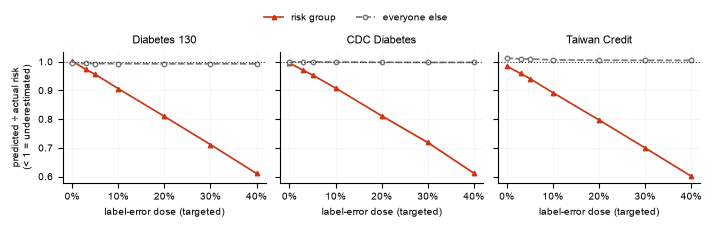

In [5]:
import matplotlib as mpl, matplotlib.pyplot as plt
mpl.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                     "font.size": 7.5, "axes.titlesize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
                     "legend.fontsize": 7, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.5,
                     "savefig.dpi": 300, "savefig.bbox": "tight", "pdf.fonttype": 42, "ps.fonttype": 42})
NAMES = {"diabetes130": "Diabetes 130", "cdcdiabetes": "CDC Diabetes", "taiwancredit": "Taiwan Credit"}
def ci(s):
    return 1.96 * s.std(ddof=1) / np.sqrt(s.count())
tg = cd[cd.mechanism == "targeted"]
fig, axes = plt.subplots(1, 3, figsize=(7.0, 1.9), sharey=True, constrained_layout=True)
for ax, d in zip(axes, DATASETS):
    for part, col, mk, ls, lab in (("group", "#CC3311", "^", "-", "risk group"),
                                   ("rest", "#777777", "o", "--", "everyone else")):
        a = tg[tg.dataset == d].groupby("dose")[f"{part}_ratio"].agg(["mean", ci])
        ax.plot(a.index, a["mean"], color=col, marker=mk, ls=ls, ms=3.2, lw=1.2, label=lab,
                mfc="white" if part == "rest" else col)
        ax.fill_between(a.index, a["mean"] - a["ci"], a["mean"] + a["ci"], color=col, alpha=0.15, lw=0)
    ax.axhline(1, ls=":", lw=0.8, color="#333333")
    ax.set_title(NAMES[d]); ax.set_xlabel("label-error dose (targeted)")
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0)); ax.set_xticks([0, .1, .2, .3, .4])
axes[0].set_ylabel("predicted ÷ actual risk\n(< 1 = underestimated)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
out = li.FIGURES / "paper"; out.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(out / f"calibration_direction.{ext}", facecolor="white")
print("saved", out / "calibration_direction.pdf/.png")

## What to look for, and what to write
- [ ] Section 2: group ECE matches notebook 04.
- [ ] Section 3, targeted noise: the group's `group_ratio` drops below 1 as the dose rises; `rest_ratio` stays near 1.
- [ ] `group_share_flagged` falls with the dose: fewer group members cross the action threshold.

**For the paper (Results), if the check passes:** "Under targeted missed-event errors the model systematically *underestimates* the risk group's risk: at the highest dose its average predicted risk is X% of the group's actual rate (Diabetes 130 / CDC / Taiwan), while predictions for everyone else stay within Y% of their actual rate." Fill X and Y from the table in section 3.